# Tentativo 16 · 8. Un LLM grande come lettore

Non esistono modelli **di embedding** aperti più grandi di 8B (Qwen3-Embedding-8B è il più grande della sua famiglia).
Per vedere se un modello più grande legge meglio le testate, usiamo un **LLM generativo da 24 miliardi di parametri**,
**Mistral-Small-24B** (base, licenza Apache), congelato: ogni articolo diventa la **media degli stati nascosti** dei suoi
token, in due punti del modello (lo strato 27 di 40, a circa due terzi, e l'ultimo). Nessuna istruzione: il modello legge
solo il testo.

Il modello è caricato **in 4 bit** (NF4) con i calcoli in fp16: in fp16 pieno servirebbero 48 GB e la V100 ne ha 32 e non
supporta bf16 (per questo non Gemma 27B, che in fp16 dà valori fuori scala). Sopra i vettori, gli **stessi modelli lineari**
dei notebook 3 e 4, nelle stesse sei configurazioni e sugli stessi fold; le varianti con il parametro scelto nel training e
con un vettore per testata sono nel notebook 7.

| | che cosa impara | su quali articoli | come si decide la testata |
|---|---|---|---|
| **1. 5 classi** | il livello (l1…l5) | tutti | voto degli articoli |
| **2. binario** | affidabile sì/no (punteggio ≥ 60) | tutti | voto degli articoli |
| **3. binario sugli estremi** | affidabile sì/no | solo l1, l2, l4, l5 | voto degli articoli |
| **4. regressione** | il punteggio 0–100 | tutti | media dei punteggi previsti |
| **5. regressione bilanciata** | il punteggio 0–100, ogni livello pesa uguale | tutti | media dei punteggi previsti |
| **6. regressione sugli estremi** | il punteggio 0–100 | solo l1, l2, l4, l5 | media dei punteggi previsti |

Per le regressioni i 5 livelli si ricavano con le **quote del training** (le testate si ordinano per punteggio previsto
e si tagliano con le stesse quote di livelli del training) e "affidabile" = punteggio previsto ≥ 60.

In [1]:
MODELLO = "mistralai/Mistral-Small-24B-Base-2501"
MAX_TOKEN = 2048                            # ogni articolo entra intero (al più 1.500 parole)
BATCH = 4
STRATI = "27,40"                            # indici degli stati nascosti: 27 di 40 (circa due terzi) e l'ultimo
GB_GPU = 22                                 # memoria GPU libera necessaria per partire (il modello ne usa circa 19)
PROVA = 0                                   # > 0: solo quel numero di articoli per testata (prova veloce, in Results/prova)

In [2]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

import funzioni as F

warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
OUT = Path("Results/embedding"); OUT.mkdir(parents=True, exist_ok=True)
art = pd.read_csv(F.DATASET / "articoli.csv.gz")
t = pd.read_csv(F.DATASET / "testate.csv", index_col="domain")
print(f"{len(art):,} articoli di {len(t)} testate, 5 fold")
import time
if PROVA:
    art = art.groupby("domain").head(PROVA).reset_index(drop=True); OUT = Path("Results/prova/embedding"); OUT.mkdir(parents=True, exist_ok=True)
    print(f"PROVA: {len(art):,} articoli")
NOME = MODELLO.split("/")[-1]
STRATI = [int(s) for s in str(STRATI).split(",")]
CARTELLE = {s: OUT / f"{NOME}_strato{s}" for s in STRATI}
registra = lambda m: print(time.strftime("%H:%M:%S"), m, flush=True)

25,524 articoli di 226 testate, 5 fold


## 1. I vettori
Una volta sola, senza etichette; si salvano (uno per strato). Circa 4,5 ore sulla V100; se si interrompe, riparte dal
lavoro salvato.

In [3]:
# 1.1 un vettore per articolo e per strato
pronti = lambda c: (c / "embedding.npy").exists() and np.array_equal(np.load(c / "embedding_article_id.npy"), art.article_id.to_numpy())
if all(pronti(c) for c in CARTELLE.values()):
    E = {s: np.load(c / "embedding.npy") for s, c in CARTELLE.items()}
else:
    F.aspetta_gpu(GB_GPU, registra)
    E = F.embedding_llm(art.text.tolist(), MODELLO, MAX_TOKEN, BATCH, STRATI, registra, file_parziale=OUT / f"{NOME}_parziale.npy")
    for s, c in CARTELLE.items():
        c.mkdir(parents=True, exist_ok=True); np.save(c / "embedding.npy", E[s]); np.save(c / "embedding_article_id.npy", art.article_id.to_numpy())
    (OUT / f"{NOME}_parziale.npy").unlink(missing_ok=True)
for s in STRATI:
    print(f"strato {s}: {E[s].shape[0]:,} articoli, vettori di {E[s].shape[1]} dimensioni, tutti finiti: {np.isfinite(E[s]).all()}")

Loading checkpoint shards:   0%|          | 0/10 [00:00<?, ?it/s]

Loading checkpoint shards:  10%|█         | 1/10 [00:05<00:49,  5.48s/it]

Loading checkpoint shards:  20%|██        | 2/10 [00:12<00:48,  6.11s/it]

Loading checkpoint shards:  30%|███       | 3/10 [00:18<00:44,  6.32s/it]

Loading checkpoint shards:  40%|████      | 4/10 [00:25<00:38,  6.47s/it]

...

20:32:01 22,404/25,524 articoli (11624 s)


20:46:01 23,204/25,524 articoli (12465 s)


21:00:57 24,004/25,524 articoli (13361 s)


21:17:12 24,804/25,524 articoli (14335 s)


strato 27: 25,524 articoli, vettori di 5120 dimensioni, tutti finiti: True
strato 40: 25,524 articoli, vettori di 5120 dimensioni, tutti finiti: True


## 2. I sei modelli lineari, fold per fold, per ogni strato
Vettori standardizzati sul training di ogni fold; stessi modelli dei notebook 3 e 4.

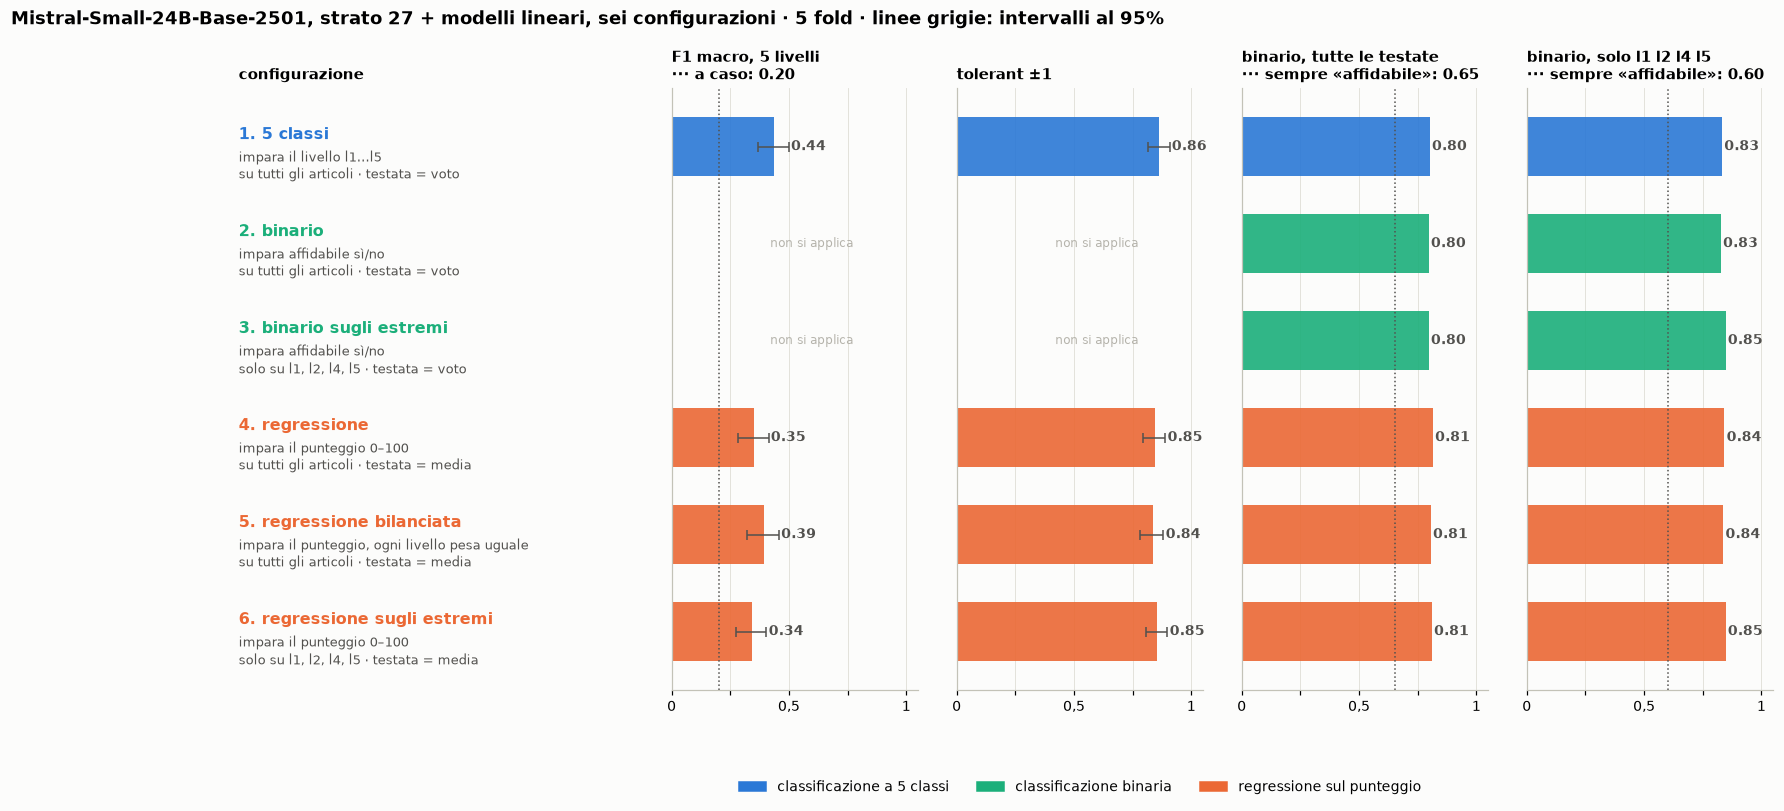

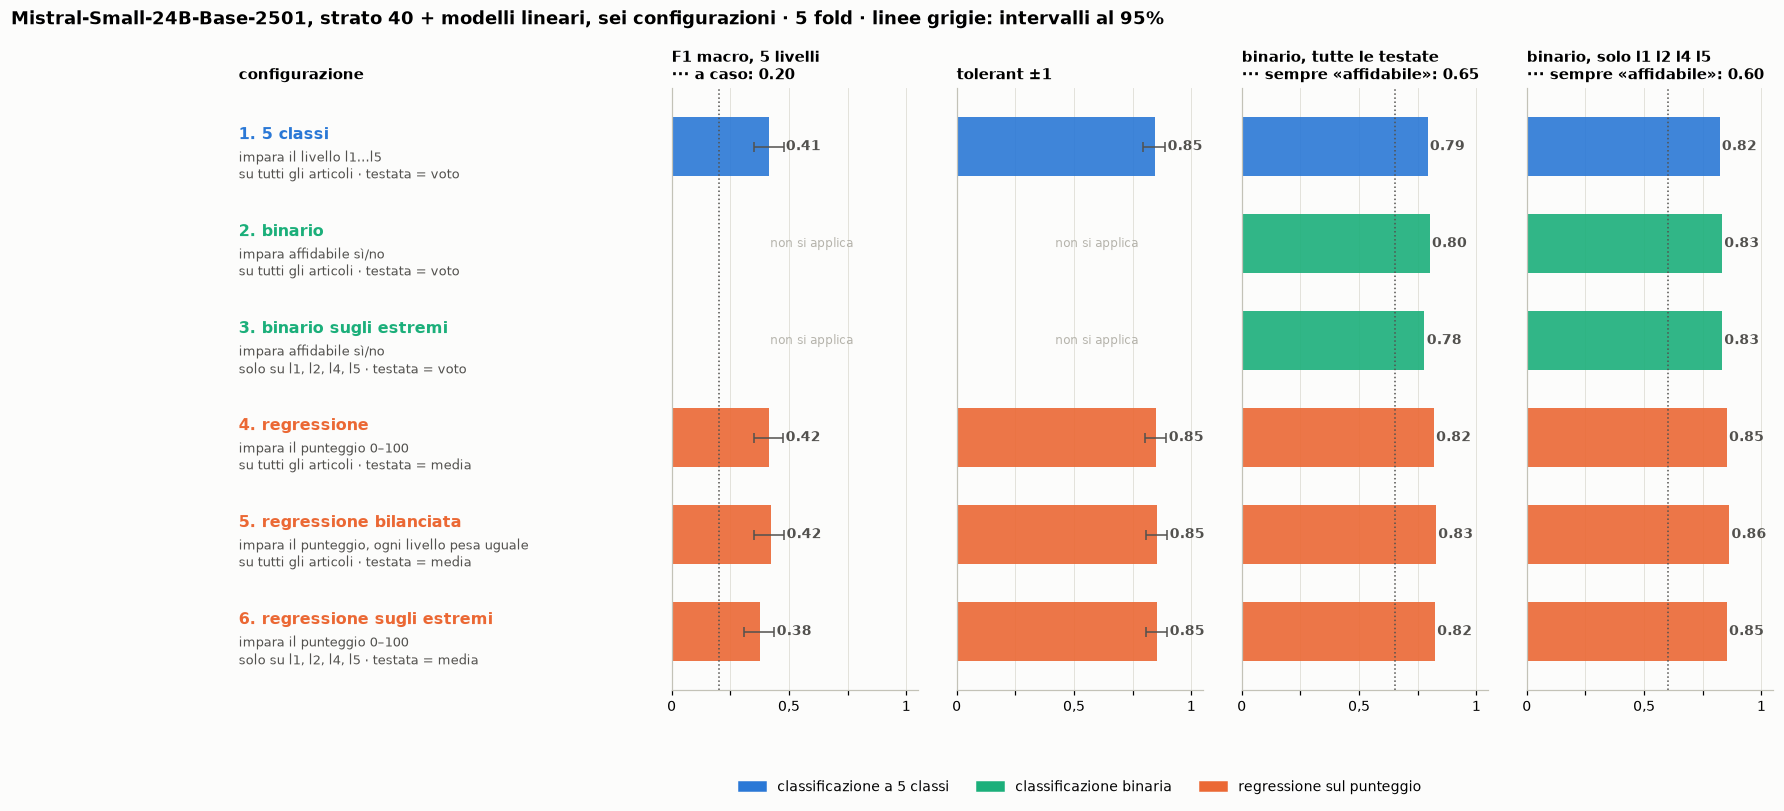

In [4]:
# 2.1 addestramento, previsione e misure
from sklearn.preprocessing import StandardScaler

def un_fold(X, k):
    tr, te = (art.fold != k).to_numpy(), (art.fold == k).to_numpy()
    s = StandardScaler().fit(X[tr])
    out = art.loc[te, ["article_id", "domain"]].reset_index(drop=True)
    return out.assign(**F.modelli_lineari(s.transform(X[tr]), s.transform(X[te]), art.label.to_numpy()[tr], art.score.to_numpy()[tr]))

for s, c in CARTELLE.items():
    pa = pd.concat(Parallel(n_jobs=5)(delayed(un_fold)(E[s], k) for k in range(1, 6)), ignore_index=True)
    pa.to_csv(c / "previsioni_articoli.csv", index=False)
    T = F.testate_da_articoli(pa, t); T.to_csv(c / "previsioni_testate.csv")
    tab5, tab2 = F.misure_testate(T); tab5.to_csv(c / "cinque_livelli.csv"); tab2.to_csv(c / "binario.csv")
    F.grafico_riassunto(T, tab5, tab2, f"{NOME}, strato {s} + modelli lineari, sei configurazioni · 5 fold · linee grigie: intervalli al 95%",
                        c / "riassunto.png")